# 03 - Data Cleaning

**Goal:** fix the problems found in notebook 02, on the working sample.

- **Input:** `CSE_CIC_IDS2018_sample.parquet` (all attacks + 15% of Benign, from notebook 02)
- **Output:** `CSE_CIC_IDS2018_clean.parquet`

| Step | Problem (from notebook 02) | Action |
|---|---|---|
| 1 | Repeated header rows | Drop the rows |
| 2 | `Timestamp` column | Drop the column |
| 3 | 8 constant features | Drop the columns |
| 4 | Missing / infinite values | Drop the rows |
| 5 | Negative time values | Drop the rows |
| 6 | Duplicate rows | Drop the duplicates |
| 7 | Contradictory rows | Drop the rows |
| 8 | Very small classes | Merge the web attacks, drop classes that are too small |

The `-1` values in `Init Fwd Win Byts` / `Init Bwd Win Byts` are **kept**: they mean "not available", not an error.

In [1]:
# Imports
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive

# Mount Drive
drive.mount("/content/drive")

# Paths
BASE = Path("/content/drive/MyDrive/Projects/CSE-CIC-IDS2018")
DATA_DIR = BASE / "data" / "processed"

SEED = 42
pd.set_option("display.max_columns", 100)

Mounted at /content/drive


## 0. Load the sample

In [2]:
SAMPLE_PATH = DATA_DIR / "CSE_CIC_IDS2018_sample.parquet"
df = pd.read_parquet(SAMPLE_PATH)

print("Shape:", df.shape)
df["Label"].value_counts()

Shape: (4769628, 80)


,count
Label,
Benign,2021334
DDOS attack-HOIC,686012
DDoS attacks-LOIC-HTTP,576191
DoS attacks-Hulk,461912
Bot,286191
FTP-BruteForce,193360
SSH-Bruteforce,187589
Infilteration,161934
DoS attacks-SlowHTTPTest,139890


### Cleaning log
After each step we record the number of rows and columns, to build a summary table at the end.

In [3]:
log = []

def log_step(step):
    log.append({"step": step, "rows": len(df), "columns": df.shape[1]})
    print(f"{step}: {len(df):,} rows, {df.shape[1]} columns")

log_step("0. Start (sample)")

0. Start (sample): 4,769,628 rows, 80 columns


## 1. Drop the repeated header rows
These rows have the label `"Label"` and no real values: they are copies of the CSV header.

In [4]:
print("Header rows:", (df["Label"] == "Label").sum())

df = df[df["Label"] != "Label"]
log_step("1. Header rows")

Header rows: 59
1. Header rows: 4,769,569 rows, 80 columns


## 2. Drop the `Timestamp` column
It's not a property of the flow itself. Each attack happened on specific days, so the date would let the
model guess the label without learning the traffic behaviour (**data leakage**).

In [5]:
df = df.drop(columns=["Timestamp"])
log_step("2. Timestamp")

2. Timestamp: 4,769,569 rows, 79 columns


## 3. Drop the constant features
These 8 columns have the same value for all 16M flows (notebook 02, step 4), so they carry no information.

In [6]:
CONSTANT_COLS = ["Bwd PSH Flags", "Bwd URG Flags", "Fwd Byts/b Avg", "Fwd Pkts/b Avg",
                 "Fwd Blk Rate Avg", "Bwd Byts/b Avg", "Bwd Pkts/b Avg", "Bwd Blk Rate Avg"]

print("Unique values in the sample:")
print(df[CONSTANT_COLS].nunique().to_string())

df = df.drop(columns=CONSTANT_COLS)
feature_cols = [c for c in df.columns if c != "Label"]
log_step("3. Constant columns")
print("Features left:", len(feature_cols))

Unique values in the sample:
Bwd PSH Flags       1
Bwd URG Flags       1
Fwd Byts/b Avg      1
Fwd Pkts/b Avg      1
Fwd Blk Rate Avg    1
Bwd Byts/b Avg      1
Bwd Pkts/b Avg      1
Bwd Blk Rate Avg    1
3. Constant columns: 4,769,569 rows, 71 columns
Features left: 70


## 4. Drop the missing and infinite values
Only `Flow Byts/s` and `Flow Pkts/s` are affected (zero-duration flows). Infinite values are first turned into
NaN, then every row with a NaN is dropped. We check which classes lose rows.

In [7]:
df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)
bad = df[feature_cols].isna().any(axis=1)

print(f"Rows with NaN or Inf: {bad.sum():,}")
print(df.loc[bad, "Label"].value_counts())

df = df[~bad]
log_step("4. NaN / Inf")

Rows with NaN or Inf: 15,507
Label
Benign            14206
Infilteration      1295
FTP-BruteForce        6
Name: count, dtype: int64
4. NaN / Inf: 4,754,062 rows, 71 columns


## 5. Drop the negative time values
Only a few rows have impossible negative durations or times. The two `Init Win Byts` columns are excluded,
because their `-1` is a valid placeholder.

In [8]:
WIN_COLS = ["Init Fwd Win Byts", "Init Bwd Win Byts"]
check_cols = [c for c in feature_cols if c not in WIN_COLS]

negative = (df[check_cols] < 0).any(axis=1)
print(f"Rows with negative values: {negative.sum():,}")

df = df[~negative]
log_step("5. Negative values")

Rows with negative values: 8
5. Negative values: 4,754,054 rows, 71 columns


## 6. Drop the duplicate rows
Identical rows (all features + label) would end up in both the train and test sets and inflate the scores.
We keep the first copy of each.

In [9]:
before = df["Label"].value_counts()
df = df.drop_duplicates()
after = df["Label"].value_counts()

dup_table = pd.DataFrame({"before": before, "after": after}).fillna(0).astype(int)
dup_table["removed_%"] = (100 * (1 - dup_table["after"] / dup_table["before"])).round(1)
log_step("6. Duplicates")
dup_table.sort_values("removed_%", ascending=False)

6. Duplicates: 3,021,968 rows, 71 columns


,before,after,removed_%
Label,,,
DoS attacks-SlowHTTPTest,139890,55,100.0
FTP-BruteForce,193354,53,100.0
DDOS attack-HOIC,686012,198861,71.0
DoS attacks-Hulk,461912,145199,68.6
SSH-Bruteforce,187589,94048,49.9
Bot,286191,144535,49.5
Benign,2007120,1671165,16.7
Infilteration,160639,139341,13.3
DoS attacks-Slowloris,10990,9712,11.6


## 7. Drop the contradictory rows
After step 6 there are no exact duplicates left. So if two rows still have the **same features**, they must
have **different labels**. No model can separate them, so they are removed.

In [10]:
conflict = df.duplicated(subset=feature_cols, keep=False)

print(f"Contradictory rows: {conflict.sum():,}")
print(df.loc[conflict, "Label"].value_counts())

df = df[~conflict]
log_step("7. Contradictory rows")

Contradictory rows: 55,862
Label
Benign                      27869
Infilteration               27868
FTP-BruteForce                 52
DoS attacks-SlowHTTPTest       52
SSH-Bruteforce                  7
Brute Force -Web                7
SQL Injection                   6
Brute Force -XSS                1
Name: count, dtype: int64
7. Contradictory rows: 2,966,106 rows, 71 columns


## 8. Small classes
- The 3 web attacks (`Brute Force -Web`, `Brute Force -XSS`, `SQL Injection`) are tiny and similar → merged
  into one class **`Web-Attack`**.
- A class with fewer than `MIN_ROWS` rows after cleaning is dropped: there is not enough data to train **and**
  test on it (this can happen to `FTP-BruteForce` and `DoS attacks-SlowHTTPTest`, which were mostly duplicates).

In [11]:
MIN_ROWS = 100

web = ["Brute Force -Web", "Brute Force -XSS", "SQL Injection"]
df.loc[df["Label"].isin(web), "Label"] = "Web-Attack"

counts = df["Label"].value_counts()
too_small = counts[counts < MIN_ROWS].index.tolist()
print("Classes dropped (too small):", too_small)

df = df[~df["Label"].isin(too_small)]
log_step("8. Small classes")
df["Label"].value_counts()

Classes dropped (too small): ['DoS attacks-SlowHTTPTest', 'FTP-BruteForce']
8. Small classes: 2,966,102 rows, 71 columns


,count
Label,
Benign,1643296
DDoS attacks-LOIC-HTTP,575012
DDOS attack-HOIC,198861
DoS attacks-Hulk,145199
Bot,144535
Infilteration,111473
SSH-Bruteforce,94041
DoS attacks-GoldenEye,41392
DoS attacks-Slowloris,9712


## 9. Cleaning summary

In [12]:
log_df = pd.DataFrame(log)
log_df["rows_removed"] = (-log_df["rows"].diff()).fillna(0).astype(int)
log_df

,step,rows,columns,rows_removed
0,0. Start (sample),4769628,80,0
1,1. Header rows,4769569,80,59
2,2. Timestamp,4769569,79,0
3,3. Constant columns,4769569,71,0
4,4. NaN / Inf,4754062,71,15507
5,5. Negative values,4754054,71,8
6,6. Duplicates,3021968,71,1732086
7,7. Contradictory rows,2966106,71,55862
8,8. Small classes,2966102,71,4


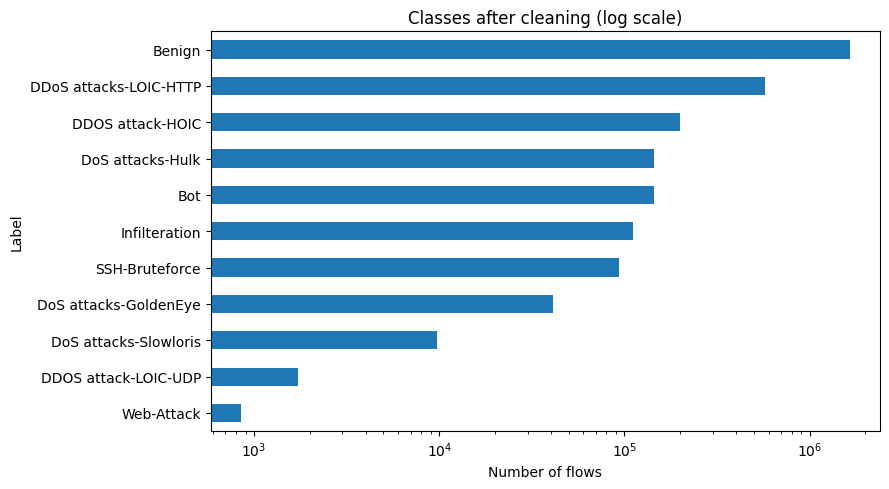

In [13]:
ax = df["Label"].value_counts().sort_values().plot(kind="barh", logx=True, figsize=(9, 5))
ax.set_title("Classes after cleaning (log scale)")
ax.set_xlabel("Number of flows")
plt.tight_layout()
plt.show()

## 10. Save the clean data

In [14]:
CLEAN_PATH = DATA_DIR / "CSE_CIC_IDS2018_clean.parquet"
df.to_parquet(CLEAN_PATH, index=False)
log_df.to_csv(DATA_DIR / "cleaning_log.csv", index=False)

print("Saved:", CLEAN_PATH)
print("Shape:", df.shape)

Saved: /content/drive/MyDrive/Projects/CSE-CIC-IDS2018/data/processed/CSE_CIC_IDS2018_clean.parquet
Shape: (2966102, 71)


## Interpretation (fill in after running)
- **Rows removed in total:** 1,803,526 (37.8%), mostly by step **6 (Duplicates)**
- **Classes affected the most by duplicates:** `DoS attacks-SlowHTTPTest` and `FTP-BruteForce` (both ~100.0% removed), followed by `DDOS attack-HOIC` (71.0%) and `DoS attacks-Hulk` (68.6%)
- **Contradictory rows:** 55,862 (almost entirely shared between `Benign` and `Infilteration` with 27,869 vs. 27,868 rows)
- **Classes dropped or merged:** `Brute Force -Web`, `Brute Force -XSS`, and `SQL Injection` were merged into `Web-Attack`. `DoS attacks-SlowHTTPTest` and `FTP-BruteForce` were dropped because they fell below the 100-row threshold after cleaning.
- **Final dataset:** 2,966,102 rows, 70 features, 11 classes